## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

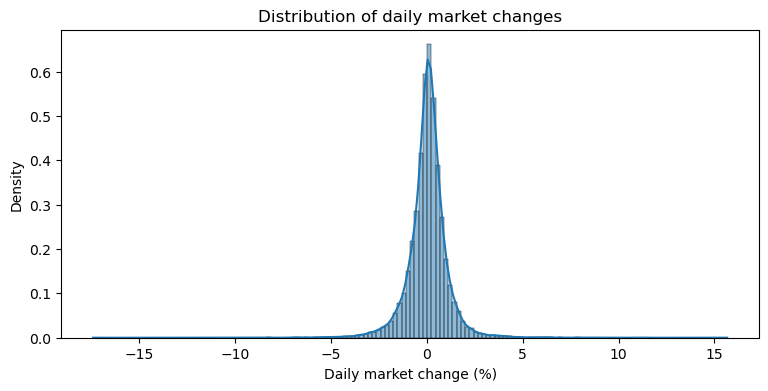

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

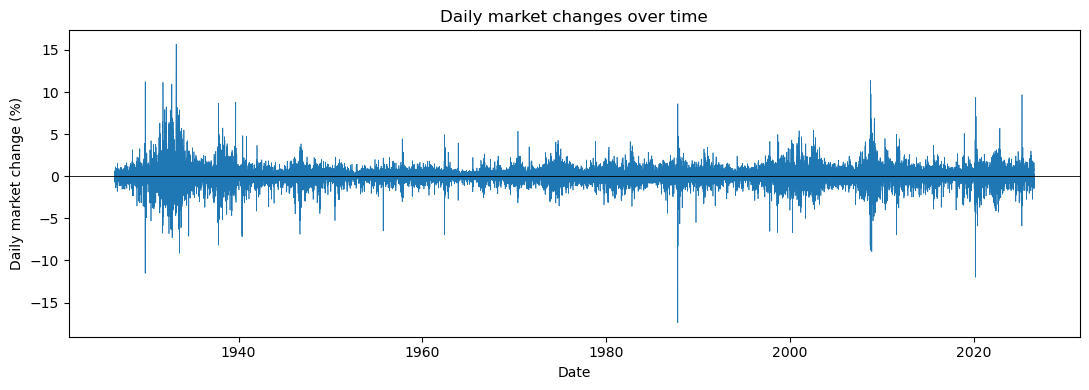

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [28]:
df['market_return_pct_i'] = (df['market_return_pct'] > 0).where(df['market_return_pct'].notna())
df['y_t'] = df['market_return_pct_i'].map({False:'Up', True:'Down (and flat)'})
df['y_tp1'] = df['market_return_pct_i'].shift(-1).map({False:'Up', True:'Down (and flat)'}) 

In [9]:
#joint
tab_joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab_joint

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.318996,0.228142
Up,0.228142,0.224720


In [10]:
#marginal 
tab_marginal = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
tab_marginal

y_tp1,Down (and flat),Up,All
y_t,,,
Down (and flat),0.318996,0.228142,0.547138
Up,0.228142,0.224720,0.452862
All,0.547138,0.452862,1.000000


In [11]:
#conditional 
tab_conditional = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab_conditional

y_tp1,Down (and flat),Up
y_t,,
Down (and flat),0.583026,0.416974
Up,0.503779,0.496221


Looking at the marginal pmf, Down (and flat) transition seems to be more common as the down and flat transition makes up about 54.7%. of the data where the up transition makes up about 45.3% of the data. 
Looking at the conditional pmf, you are more likely to transition to an Up day from a Up day, as from down and flat to up is around 0.417 while from up to up is around 0.496.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [29]:
df['pct_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['pct_bin']
df['y_tp1'] = df['pct_bin'].shift(-1)
df['y_t'].value_counts()

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

9785 days fall into small gain, 7452 days fall into small loss, 3441 days fall into near zero, 2859 days fall into large gain, and 2759 days fall into large loss. Small gain is the most common and large loss is the least common.

In [30]:
#joint
tab_joint = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize=True)
tab_joint

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


In [31]:
#marginal
tab_marginal = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
tab_marginal

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


Transition to small gain seems to be the most likely to occur as it has the highest marginal probability. 

In [32]:
#conditional 
tab_conditional = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize='index')
tab_conditional

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


1. Small gain and small loss is the two most likely futures for large loss. 
2. Small gain and small loss is the two most likely futures for small loss. 
3. Small gain and small loss is the two most likely futures for near zero. 
4. Small gain and small loss is the two most likely futures for small gain. 
5. Small gain and small loss is the two most likely futures for large gain. 

It is not very close to a uniform mass function. Small gain and small loss dominates the future states as seen above. Some pairs are below 0.1 and some are close to 0.4 indicating that each row is really not close to a uniform mass function with probability .2 over each transition. 

It is relatively difficult to predict the next state as although it is not close to a uniform, there is also no majority future state in each row. Again, it is not uniform but the probability is spread across all five categories for all five current states which would make it hard to confidently say what would the next day be like. 


In [33]:
#conditional expectation
df['market_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['market_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


- Given large loss, the expected percen return for tomorrow is arounf -0.038.
- Given small loss, the expected percen return for tomorrow is arounf -0.044.
- Given near zero, the expected percen return for tomorrow is arounf 0.015.
- Given small gain, the expected percen return for tomorrow is arounf 0.107.
- Given large gain, the expected percen return for tomorrow is arounf 0.163.

The range becomes larger as you move away from your current state being near zero. The extremes (min and max) because larger values (in absolute terms) as you look at large loss or large gain. Large loss has the highest standard deviation for tomorrow's percent returns. Volatility is larger for current state being in large loss or large gain. Regardless, looking at the min and max for all five states, there is a chance for one to have a high gain or loss the next day.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [34]:
df['pct_bin'] = pd.qcut(
    df['market_return_pct'], q=21
)
df['y_t'] = df['pct_bin']
df['y_tp1'] = df['pct_bin'].shift(-1)

In [35]:
#joint
joint_21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
joint_21_subtract = joint_21 - (1/21)**2

[Text(0.5, 1.0, 'Joint PMF')]

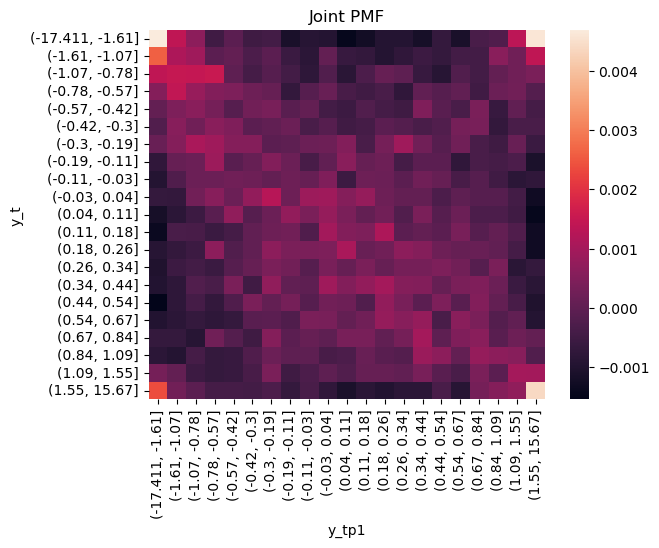

In [36]:
sns.heatmap(joint_21_subtract).set(title='Joint PMF')

**Do you see any obvious patterns? Explain. unsure
The pair between a bin towards the middle and an extreme bin for te second day seems unlikely. All pairs are near zeros meaning the mass is spread out. 

In [22]:
#conditional 
conditional_21 = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize='index')
conditional_21_subtract = conditional_21 - (1/21)**2

[Text(0.5, 1.0, 'Conditional PMF')]

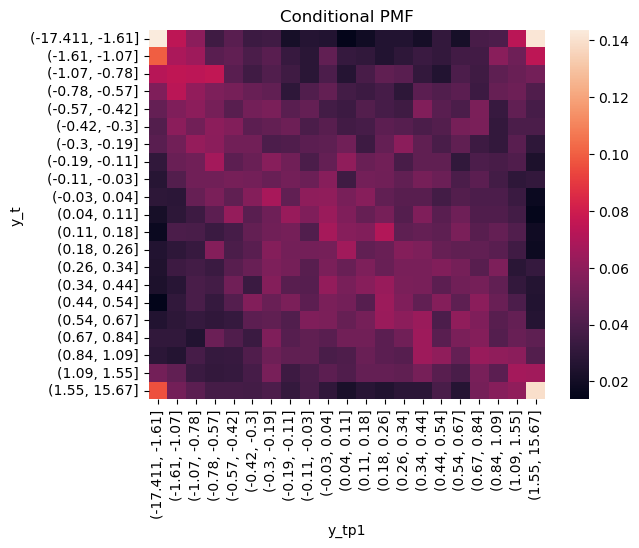

In [23]:
sns.heatmap(conditional_21_subtract).set(title='Conditional PMF')

given extreme loss likely to have extreme loss again. but also liekly to have extreme gain. extreme gain to extreme loss more likely than other pairs as well as extreme gain to extreme gain relatively more likely than other pairs. 

In [54]:
df['y_t'] = pd.qcut(
    df['market_return_pct'], q=21, labels=False
)
df['y_tp1'] = df['y_t'].shift(-1)

In [ ]:

#how to plot against the bins
bins21 = range(21)
all_min = []
all_mean = []
all_max = []
for x in sorted(df['y_t'].dropna().unique()):
    tomorrow = df.loc[df['y_t'] == x, 'y_tp1'].dropna()   # tomorrow's values for days where today == x
    all_min.append(tomorrow.min())
    all_mean.append(tomorrow.mean())
    all_max.append(tomorrow.max())



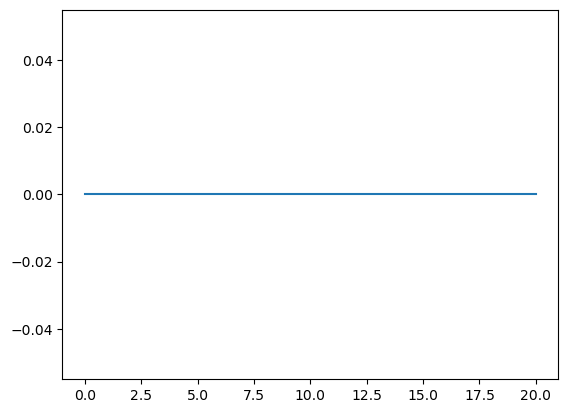

In [59]:
plt.plot(bins21,all_min)


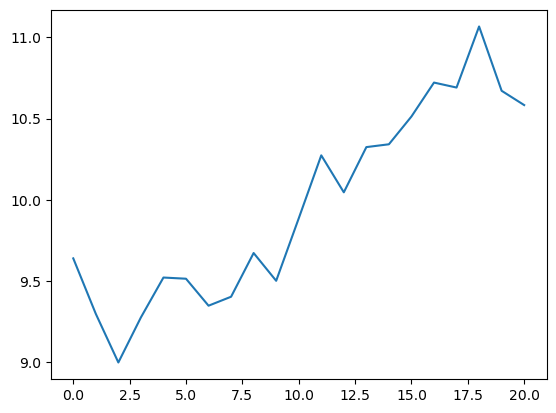

In [61]:
plt.plot(bins21,all_mean)

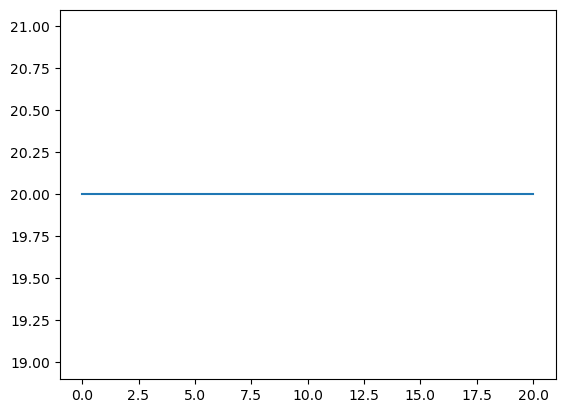

In [62]:
plt.plot(bins21,all_max)

 Do you see any obvious patterns? Explain.

In [63]:
#standard deviation
all_sd=[]
for x in sorted(df['y_t'].dropna().unique()):
    tomorrow = df.loc[df['y_t'] == x, 'y_tp1'].dropna()   # tomorrow's values for days where today == x
    all_sd.append(np.std(tomorrow))


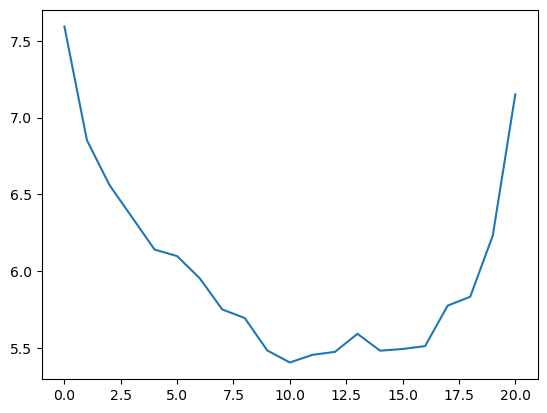

In [64]:
plt.plot(bins21,all_sd)

Standard deviation increase as you move into the extreme side of the bins Do you see any obvious patterns? Explain.

How easy is it to predict the market?
It is not easy to predict the market, clearly shown by the heatmap above. The probability mass is spread out. 